Rows, columns: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


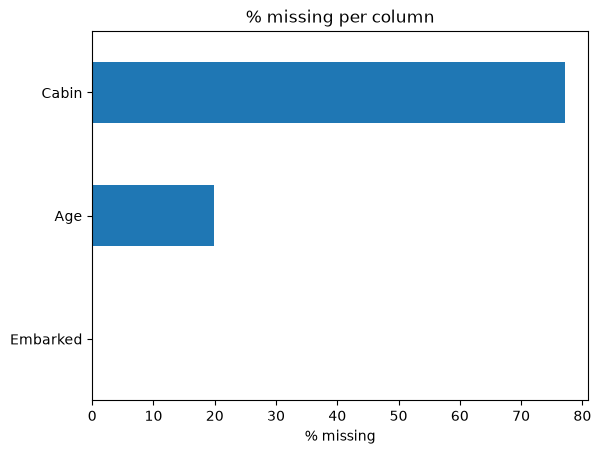

Rows: 894
Duplicates: 3


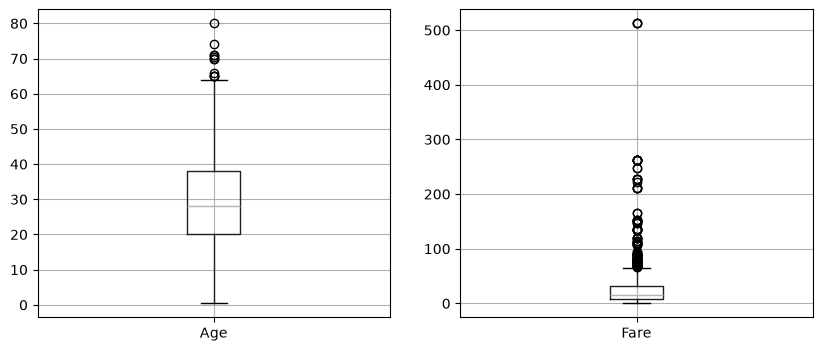

Fare: normal range is -26.72 to 65.63
Number of Fare outliers: 116


,Name,Pclass,Fare
258,"Ward, Miss. Anna",1,512.3292
737,"Lesurer, Mr. Gustave J",1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
27,"Fortune, Mr. Charles Alexander",1,263.0000
341,"Fortune, Miss. Alice Elizabeth",1,263.0000


In [7]:
import pandas as pd
df = pd.read_csv('C:\\janki\\ds-october-2026\\archive\\train.csv')
df.head()
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
#  First Look
print("Rows, columns:", df.shape)
df.info()
df.describe()
df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(1)
missing_pct[missing_pct > 0].sort_values(ascending=False)
missing_pct[missing_pct > 0].sort_values().plot(kind="barh", title="% missing per column")
plt.xlabel("% missing")
plt.show()
df.duplicated().sum()
df_with_dupes = pd.concat([df, df.head(3)], ignore_index=True)
print("Rows:", len(df_with_dupes))
print("Duplicates:", df_with_dupes.duplicated().sum())
df_with_dupes[df_with_dupes.duplicated(keep=False)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df.boxplot(column="Age", ax=axes[0])
df.boxplot(column="Fare", ax=axes[1])
plt.show()

def iqr_bounds(column):
    q1 = column.quantile(0.25)
    q3 = column.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

lower, upper = iqr_bounds(df["Fare"])
print(f"Fare: normal range is {lower:.2f} to {upper:.2f}")

fare_outliers = df[(df["Fare"] < lower) | (df["Fare"] > upper)]
print("Number of Fare outliers:", len(fare_outliers))
fare_outliers[["Name", "Pclass", "Fare"]].sort_values("Fare", ascending=False).head()